In [36]:
   import pandas as pd
   import matplotlib.pyplot as plt
   import seaborn as sns
   print("Ready!")

Ready!


In [37]:
meta = pd.read_csv("Restaurant names and Metadata.csv")
reviews = pd.read_csv("Restaurant reviews.csv")
print(meta.shape, reviews.shape)

(105, 6) (10000, 7)


In [38]:
for name, df in [("meta", meta), ("reviews", reviews)]:
    print(f"--- {name} ---")
    print("Shape:", df.shape)
    print(df.dtypes, "\n")
    print("Missing values:\n", df.isna().sum(), "\n")
    print("Duplicate rows:", df.duplicated().sum(), "\n")
    display(df.head())

--- meta ---
Shape: (105, 6)
Name           str
Links          str
Cost           str
Collections    str
Cuisines       str
Timings        str
dtype: object 

Missing values:
 Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64 

Duplicate rows: 0 



,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


--- reviews ---
Shape: (10000, 7)
Restaurant      str
Reviewer        str
Review          str
Rating          str
Metadata        str
Time            str
Pictures      int64
dtype: object 

Missing values:
 Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64 

Duplicate rows: 36 



,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


In [39]:
print(reviews["Rating"].value_counts())
print(meta["Cost"].head())

Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
2.5       19
1.5        9
Like       1
Name: count, dtype: int64
0      800
1      800
2    1,300
3      800
4    1,200
Name: Cost, dtype: str


In [40]:
rev = reviews.copy()

rev = rev.drop_duplicates()
rev = rev.dropna(subset=["Rating"])
rev = rev[rev["Rating"] != "Like"]
rev["Rating"] = rev["Rating"].astype(float)
rev["Time"] = pd.to_datetime(rev["Time"], format="%m/%d/%Y %H:%M")

rev["Reviewer_Reviews"] = rev["Metadata"].str.extract(r"(\d+)\s+Review")[0].fillna(0).astype(int)
rev["Reviewer_Followers"] = rev["Metadata"].str.extract(r"(\d+)\s+Follower")[0].fillna(0).astype(int)
rev = rev.drop(columns=["Metadata"])

print(rev.shape)
print(rev.dtypes)

(9961, 8)
Restaurant                       str
Reviewer                         str
Review                           str
Rating                       float64
Time                  datetime64[us]
Pictures                       int64
Reviewer_Reviews               int64
Reviewer_Followers             int64
dtype: object


In [41]:
m = meta.copy()
m["Cost"] = m["Cost"].str.replace(",", "").astype(int)

print(m.dtypes)
print(m["Cost"].describe())

Name             str
Links            str
Cost           int64
Collections      str
Cuisines         str
Timings          str
dtype: object
count     105.000000
mean      861.428571
std       510.149730
min       150.000000
25%       500.000000
50%       700.000000
75%      1200.000000
max      2800.000000
Name: Cost, dtype: float64


In [42]:
   df = rev.merge(m, left_on="Restaurant", right_on="Name", how="left")
   print(df.shape)
   df.head(3)

(9961, 14)


,Restaurant,Reviewer,Review,Rating,Time,Pictures,Reviewer_Reviews,Reviewer_Followers,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5.0,2019-05-25 15:54:00,0,1,2,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5.0,2019-05-25 14:20:00,0,3,2,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5.0,2019-05-24 22:54:00,0,2,3,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"


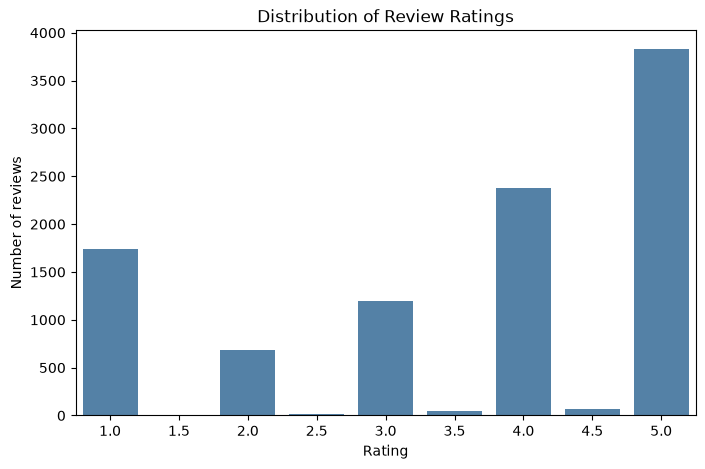

In [43]:
#How are ratings distributed?
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Rating", color="steelblue")
plt.title("Distribution of Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of reviews")
plt.show()

Ratings are polarized. 5-star is the most common rating (about 3,800 reviews), followed by 4-star (about 2,400), but 1-star reviews (about 1,700) outnumber 2-star ones (about 700). This suggests people tend to leave a review when they are either very happy or very unhappy. Half-star ratings like 1.5 and 4.5 are rare.

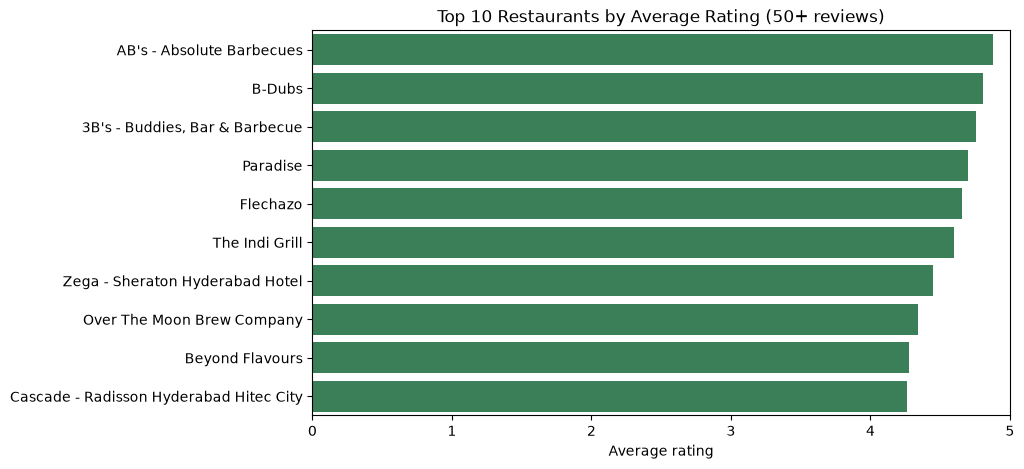

In [44]:
#Which restaurants have the highest average rating?
stats = df.groupby("Restaurant").agg(
    avg_rating=("Rating", "mean"),
    n_reviews=("Rating", "count"),
    cost=("Cost", "first")
).reset_index()

top10 = stats[stats["n_reviews"] >= 50].sort_values("avg_rating", ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(data=top10, y="Restaurant", x="avg_rating", color="seagreen")
plt.title("Top 10 Restaurants by Average Rating (50+ reviews)")
plt.xlabel("Average rating")
plt.ylabel("")
plt.xlim(0, 5)
plt.show()

AB's Absolute Barbecues, B-Dubs and 3B's Buddies, Bar & Barbecue have the highest average ratings, all around 4.8 to 4.9 out of 5. Paradise and Flechazo are close behind. Even the 10th restaurant averages about 4.3, so the gap between the top 10 is small. I only included restaurants with at least 50 reviews so a few enthusiastic ratings couldn't push a restaurant to the top.

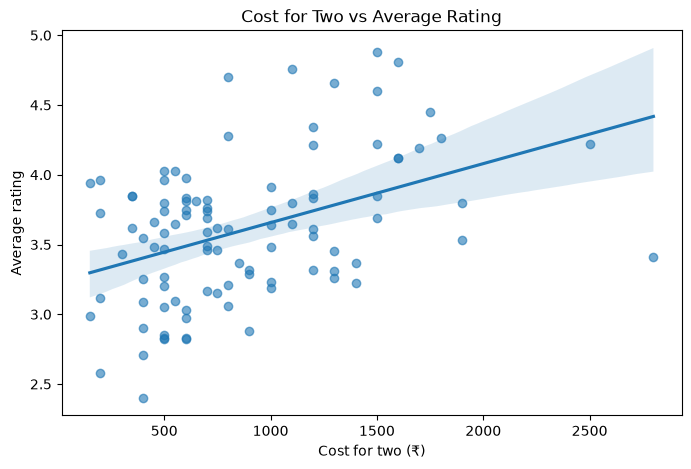

Correlation: 0.42


In [45]:
#Do pricier restaurants get better ratings?
plt.figure(figsize=(8, 5))
sns.regplot(data=stats, x="cost", y="avg_rating", scatter_kws={"alpha": 0.6})
plt.title("Cost for Two vs Average Rating")
plt.xlabel("Cost for two (₹)")
plt.ylabel("Average rating")
plt.show()

print("Correlation:", stats["cost"].corr(stats["avg_rating"]).round(2))

Pricier restaurants tend to have higher average ratings, but the link is loose. The trend line slopes upward and the correlation is [your number], yet the dots are widely scattered. Some cheap restaurants (under ₹500 for two) rate above 4.0, and the most expensive one (about ₹2,800) averages only about 3.4. This data only shows a relationship, not that spending more causes better ratings.

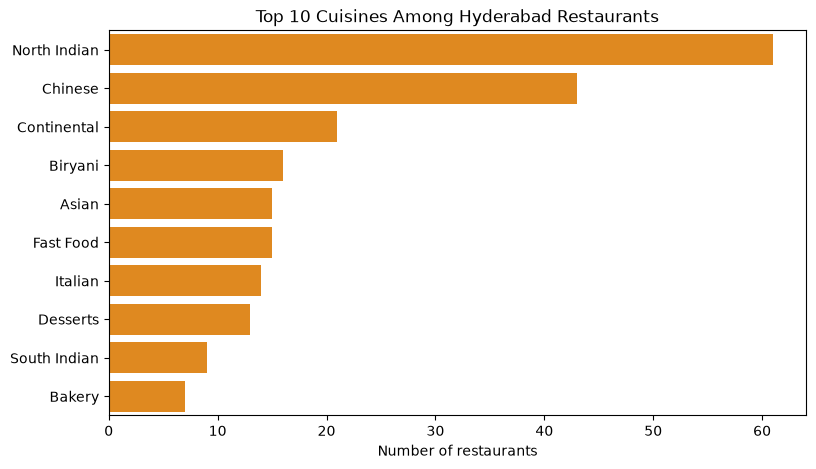

In [46]:
#Which cuisines are most common?
cuisines = m.assign(Cuisine=m["Cuisines"].str.split(",")).explode("Cuisine")
cuisines["Cuisine"] = cuisines["Cuisine"].str.strip()
top_c = cuisines["Cuisine"].value_counts().head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_c.values, y=top_c.index, color="darkorange")
plt.title("Top 10 Cuisines Among Hyderabad Restaurants")
plt.xlabel("Number of restaurants")
plt.ylabel("")
plt.show()

North Indian is the most common cuisine, listed by about 61 of the 105 restaurants (roughly 58%). Chinese is second with about 43, and Continental is a distant third with about 21. Biryani, Asian, Fast Food and Italian each appear in around 14 to 16 restaurants. Restaurants can list several cuisines, so these counts overlap and don't add up to 105.

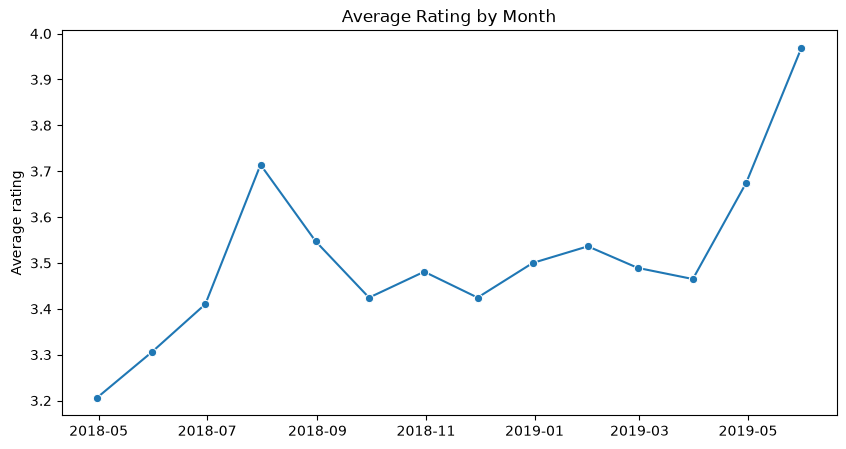

In [47]:
#Have ratings changed overtime?
monthly = df.set_index("Time").resample("ME")["Rating"].agg(["mean", "count"]).reset_index()
monthly = monthly[(monthly["count"] >= 30) & (monthly["Time"] >= "2018-04-01")]

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x="Time", y="mean", marker="o")
plt.title("Average Rating by Month")
plt.xlabel("")
plt.ylabel("Average rating")
plt.show()

Average monthly ratings were lowest in spring 2018 (around 3.2 to 3.4), peaked briefly in mid-2018 (about 3.7), then stayed fairly flat at around 3.4 to 3.5 through early 2019. In the last two months of the data they rise to nearly 4.0. The chart starts in April 2018 and only includes months with at least 30 reviews, because earlier months had too few reviews to trust. This data can't explain why ratings moved, since a monthly average can shift just because different restaurants were reviewed that month.

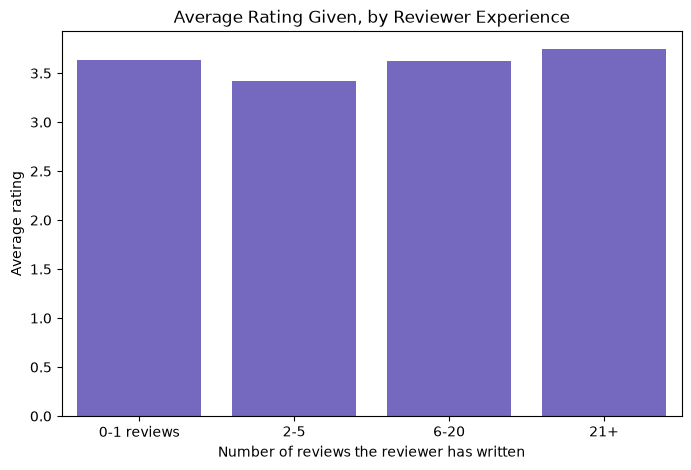

In [48]:
#Do experienced reviewers rate differently?
df["Reviewer_Type"] = pd.cut(
    df["Reviewer_Reviews"],
    bins=[-1, 1, 5, 20, 100000],
    labels=["0-1 reviews", "2-5", "6-20", "21+"]
)

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="Reviewer_Type", y="Rating", color="slateblue", errorbar=None)
plt.title("Average Rating Given, by Reviewer Experience")
plt.xlabel("Number of reviews the reviewer has written")
plt.ylabel("Average rating")
plt.show()

Reviewer experience makes little difference to the rating given. Average ratings fall between about 3.4 and 3.75 across all four groups. Reviewers with 21 or more reviews rate slightly higher (about 3.75), and those with 2 to 5 reviews slightly lower (about 3.4), but there is no steady trend as experience grows. The differences are small, so this data gives no sign that experienced reviewers are harsher or more generous.

In [49]:
print(df.set_index("Time").resample("ME")["Rating"].count())

Time
2016-05-31       2
2016-06-30       9
2016-07-31       3
2016-08-31       2
2016-09-30       1
2016-10-31       7
2016-11-30      10
2016-12-31       9
2017-01-31       7
2017-02-28      11
2017-03-31       6
2017-04-30       4
2017-05-31      10
2017-06-30      10
2017-07-31      18
2017-08-31      28
2017-09-30      22
2017-10-31      19
2017-11-30      36
2017-12-31      42
2018-01-31      24
2018-02-28      10
2018-03-31      46
2018-04-30     119
2018-05-31     183
2018-06-30     273
2018-07-31    1310
2018-08-31     647
2018-09-30     622
2018-10-31     603
2018-11-30     523
2018-12-31     543
2019-01-31     621
2019-02-28     698
2019-03-31    1013
2019-04-30    1124
2019-05-31    1346
Freq: ME, Name: Rating, dtype: int64


In [50]:
print(monthly["Time"].min(), monthly["Time"].max())
print(len(monthly), "months in the chart")

2018-04-30 00:00:00 2019-05-31 00:00:00
14 months in the chart
